Principal component analysis of the yield curve

In this script we illustrate estimation of static principal-component LFM of changes in yield to maturity
of a zero-coupon bond

In [39]:
from numpy import arctan, argmax, argsort, average, cos, cumsum, diag, ix_,\
                  linspace, ones_like, outer, pi, sin, sqrt, sum, tile
from numpy.linalg import eig, eigh
from numpy.random import multivariate_normal
from pandas import read_csv
from seaborn import lineplot, barplot
from matplotlib.pyplot import show, axes, locator_params

In [40]:
# find the ROOT & DATA folder.

from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_DIR = ROOT / "data"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # lets 'from arpym...' work from any subfolder

From  the local database where db_pca_yield_data has been created
from the script s_yield_change_correlation we upload the changes in
yield to maturity of a zero coupon bond.

In [46]:
db_pca_yield_data = read_csv(DATA_DIR/'temporary-databases/db_pca_yield_data.csv')
# number of times to maturity
n_bar = int(db_pca_yield_data['n_bar'][0])
# times to maturity
# :n_bar slices cuts off the nan values
tau = db_pca_yield_data['tau'].values[:n_bar]
# sample mean vector
m_hat_hfp_x = db_pca_yield_data['m_hat_hfp_x'].values[:n_bar]
# sample covariance matrix
s2_hat_hfp_x = db_pca_yield_data['s2_hat_hfp_x'].values[:n_bar**2].reshape(n_bar, n_bar)
# sample standard deviation vector
s_hat_hfp_x = db_pca_yield_data['s_hat_hfp_x'].values[:n_bar]
# analytical fit parameter
gamma_star = db_pca_yield_data['gamma_star'][0]
# number of monitoring times
t_bar = int(db_pca_yield_data['t_bar'][0])
# yields - reshaped to suit what is was saved as - maturities x days
y = db_pca_yield_data['y'].values.reshape(n_bar, t_bar)

1. Compute empirical eigenvectors, eigenvalues and r-squared

PCA on the sample covariance

Eigen-Decomposition - gives the eigenvalues and eigenvectors of the 33x33 covariance, and then sorted largest first.

 Sign Fix - making sure +ve/largest eigenvalues are plotted every run

R^2  is the same as my homework

The plot is the payoff of the unit
e^ - all maturities move the same way
e^2 - short and long ends move in opposite directions
e^3 the middle moves against both ends

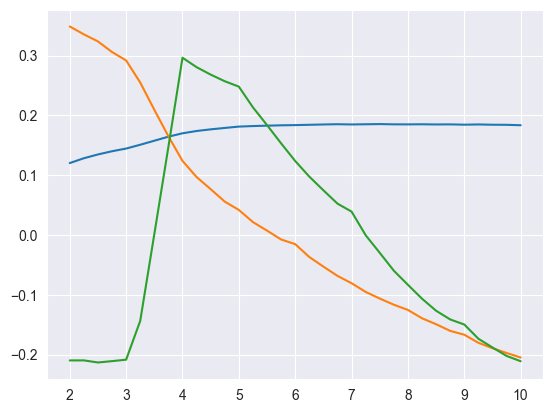

In [49]:
# eigenvalues and eigenvectors of sample covariance
lam_hat, e_hat = eig(s2_hat_hfp_x)
# computing the sorting 1 time
idx = argsort(-lam_hat)
# eigenvalues sorted in descending order
lam_hat = lam_hat[idx]
# eigenvectors sorted according to eigenvalues
e_hat = e_hat[:, idx]
# largest element in each eigenvector has a positive sign
ind = argmax(abs(e_hat), axis=0)
ind = diag(e_hat[ind, :]) < 0
e_hat[:, ind] = -e_hat[:, ind]
# empirical r-squared
r2_hat = cumsum(lam_hat)/sum(lam_hat)

############# plot #############
# first three eigenvectors
lineplot(x=tau, y=e_hat[:, 0])
lineplot(x=tau, y=e_hat[:, 1])
lineplot(x=tau, y=e_hat[:, 2]);

2. Compute theoretical eigenvalues and r-squared

Theory vs data for the eigenvalues

The bars are the real eigenvalues, both plot scaled so the first equals 1.

The red line is what y* predicts.

A close match means "correlation decays with distance" is enough to explain why yields have
3 dominant factors.

A small y (slow decay) makes the eigenvalues drop off fast, which means fewer factors.

Thats the staircase from my homework, explained by a formula.

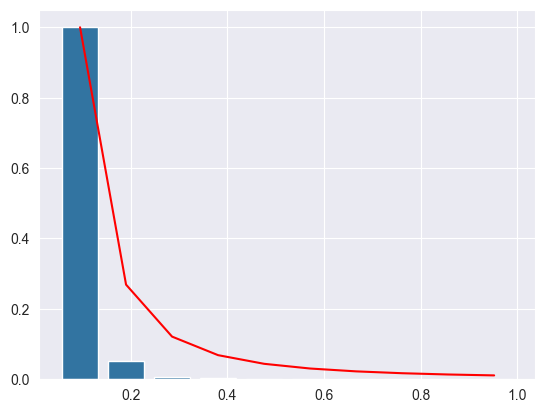

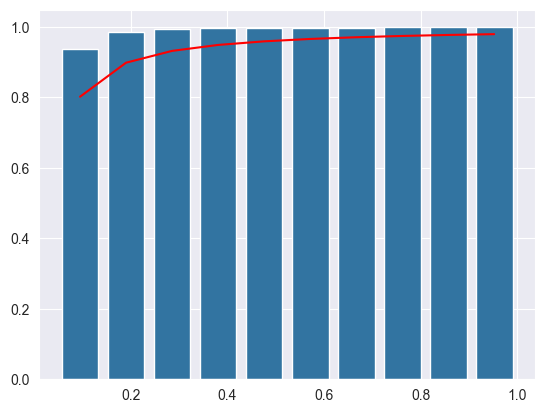

In [54]:
s2 = average(s_hat_hfp_x)**2  # average volatility
k_bar = 10  # maximum number of factors to consider (you can change it)
omega = pi/len(tau)*linspace(1, k_bar, k_bar)  # frequencies
lam_omega = 2*s2*gamma_star/(gamma_star**2 + omega**2)  # eigenvalues
r2_omega = 2/pi*arctan(omega/gamma_star)  # theoretical r-squared

############################# plots #############################
# eigenvalues
barplot(x=omega, y=lam_hat[:k_bar]/lam_hat[0], native_scale=True)
lineplot(x=omega, y=lam_omega/lam_omega[0], color='red')
show()

# r-squared
barplot(x=omega, y=r2_hat[:k_bar], native_scale=True)
lineplot(x=omega, y=r2_omega, color='red')
show();

3. Demonstrate shift effect, steepening effect and curvature effect

Shock the Curve along each eigenvector

The shock - Row K of shift is a 3-standard deviation move along eigenvector k.

The base curve 'y_shift' holds 33 copies of the starting curve, 3 times over (shock, +shock, -shock).
Each one gets its own eigenvectors shock added or subtracted.

The plots
Shock1: moves the whole curve up or down in parallel
Shock2: steepens or flattens it
Shock3: bends the middle

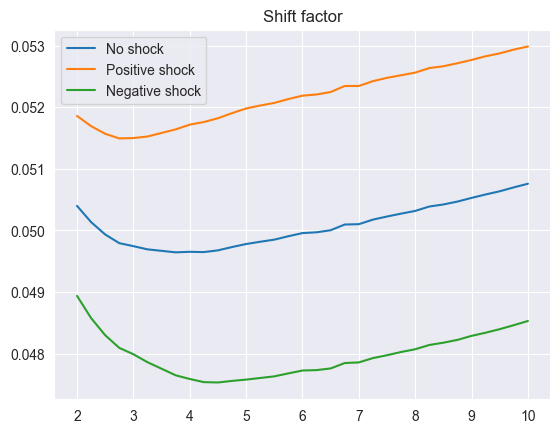

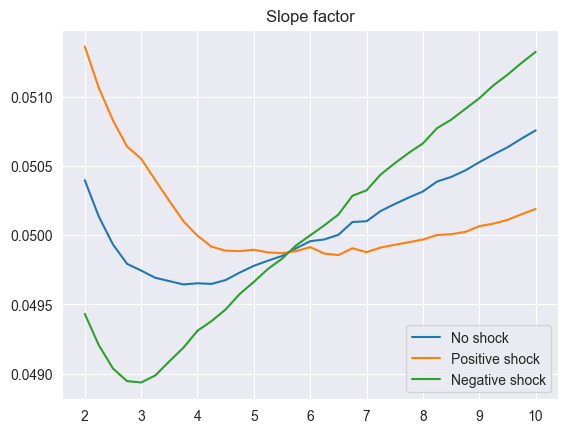

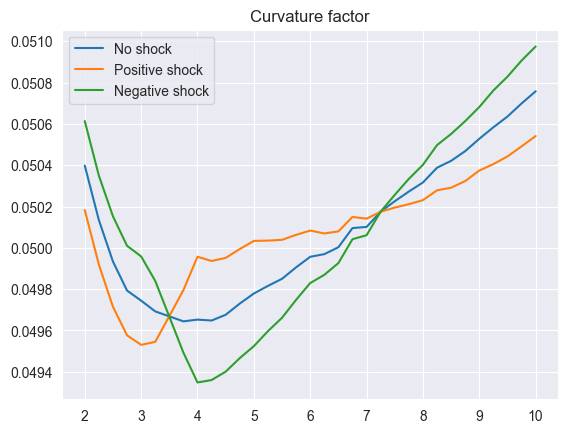

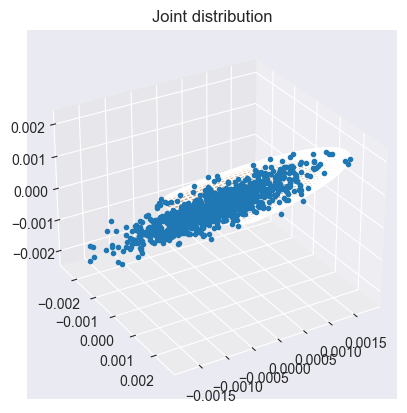

In [56]:
r = 3  # number of standard-deviation event (you can change it)
# shift from event
shift = (r*e_hat@diag(sqrt(lam_hat))).T
# initial yields to maturity
y_shift = tile(y[:, 0].reshape(n_bar, -1), (n_bar, 1, 3))
# positive shock event
y_shift[:, :, 1] = y_shift[:, :, 1] + shift
# negative shock event
y_shift[:, :, 2] = y_shift[:, :, 2] - shift

######################################## plots ########################################
# 1st factor: shift
lineplot(x=tau, y=y_shift[0, :, 0], label='No shock').set(title='Shift factor')
lineplot(x=tau, y=y_shift[0, :, 1], label='Positive shock')
lineplot(x=tau, y=y_shift[0, :, 2], label='Negative shock'); show()

# 2nd factor: steepening
lineplot(x=tau, y=y_shift[1, :, 0], label='No shock').set(title='Slope factor')
lineplot(x=tau, y=y_shift[1, :, 1], label='Positive shock')
lineplot(x=tau, y=y_shift[1, :, 2], label='Negative shock'); show()

# 3rd factor: curvature
lineplot(x=tau, y=y_shift[2, :, 0], label='No shock').set(title='Curvature factor')
lineplot(x=tau, y=y_shift[2, :, 1], label='Positive shock')
lineplot(x=tau, y=y_shift[2, :, 2], label='Negative shock'); show()

# ellipsoid
index = [0, 12, -1];
lam, e = eigh(s2_hat_hfp_x[ix_(index, index)])
s = e*sqrt(lam)
points = multivariate_normal(m_hat_hfp_x[index], s2_hat_hfp_x[ix_(index, index)], 1000)
x_ball = 3*outer(cos(linspace(0, 2*pi, 50)), sin(linspace(pi/2, pi, 50)))
y_ball = 3*outer(sin(linspace(0, 2*pi, 50)), sin(linspace(pi/2, pi, 50)))
z_ball = 3*outer(ones_like(linspace(0, 2*pi, 50)), cos(linspace(pi/2, pi, 50)))
x_ellip = m_hat_hfp_x[index][0] + s[0, 0]*x_ball + s[0, 1]*y_ball + s[0, 2]*z_ball
y_ellip = m_hat_hfp_x[index][1] + s[1, 0]*x_ball + s[1, 1]*y_ball + s[1, 2]*z_ball
z_ellip = m_hat_hfp_x[index][2] + s[2, 0]*x_ball + s[2, 1]*y_ball + s[2, 2]*z_ball
ax = axes(projection='3d')
ax.plot(points[:, 0], points[:, 1], points[:, 2], '.')
ax.plot_surface(x_ellip, y_ellip, z_ellip, alpha=0.5)
ax.view_init(29, -121); ax.invert_yaxis(); ax.set_title('Joint distribution');

Step 4: 3D ellipsoid

This is the 2D ellipse from the last notebook, now in 3D for 2y, 5y amd 10y changes

eigh on 3x3 blocks gives its axes (e) and their lengths (sqrt(gamma))

1000 points are simulated from a normal distribution with the sample mean and covariance

A sphere of radius 3 is stretch and rotated by e.sqrt(gamma) into a 3-sd ellipsoid

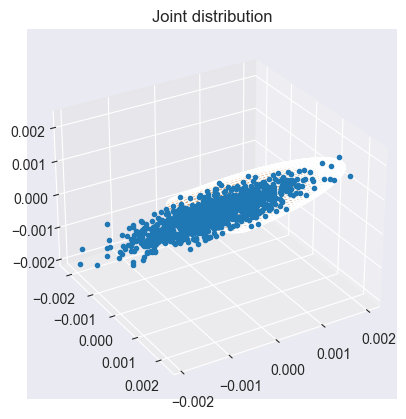

In [57]:
index = [0, 12, -1]
lam, e = eigh(s2_hat_hfp_x[ix_(index, index)])
s = e*sqrt(lam)
points = multivariate_normal(m_hat_hfp_x[index], s2_hat_hfp_x[ix_(index, index)], 1000)
x_ball = 3*outer(cos(linspace(0, 2*pi, 50)), sin(linspace(pi/2, pi, 50)))
y_ball = 3*outer(sin(linspace(0, 2*pi, 50)), sin(linspace(pi/2, pi, 50)))
z_ball = 3*outer(ones_like(linspace(0, 2*pi, 50)), cos(linspace(pi/2, pi, 50)))
x_ellip = m_hat_hfp_x[index][0] + s[0, 0]*x_ball + s[0, 1]*y_ball + s[0, 2]*z_ball
y_ellip = m_hat_hfp_x[index][1] + s[1, 0]*x_ball + s[1, 1]*y_ball + s[1, 2]*z_ball
z_ellip = m_hat_hfp_x[index][2] + s[2, 0]*x_ball + s[2, 1]*y_ball + s[2, 2]*z_ball
ax = axes(projection='3d')
ax.plot(points[:, 0], points[:, 1], points[:, 2], '.')
ax.plot_surface(x_ellip, y_ellip, z_ellip, alpha=0.5)
ax.view_init(29, -121); ax.invert_yaxis(); ax.set_title('Joint distribution'); show()